# Probability and Statistics Lab 2: random variables, and limit theorems

## General comments and instructions

-   The report must be prepared as *jupyter notebook along with compiled PDF*.
-   For each task, include
    -   the statistics obtained (like sample mean or anything else you use to complete the task) as well as histograms etc to illustrate your findings;
    -   justification of your solution (e.g. refer to the corresponding theorems from probability theory); whenever applicable, provide LaTeX formulas and derivations.
    -   conclusions (e.g. how reliable your answer is, does it agree with common sense expectations etc.).
-   Not complying with these instructions may result in point deduction.


### Work breakdown:

- NameSurname1: Zhurayev Lev
- NameSurname2: Sviatoslav Volianiuk
- NameSurname3: ...


A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list. We keep it for reproducible calculations.

In [1]:
import random
import numpy as np

team_id: int = 19

random.seed(team_id)
np.random.seed(team_id)

## Task 1. Hamming codes


In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1 \\
0 & 1 & 1 & 0 & 0 & 1 & 1 \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*


Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


In [2]:
import itertools
import matplotlib.pyplot as plt
from scipy.stats import norm, binom

p = (2 + team_id / 4) / 100      # probability that a single bit gets corrupted
print("p =", p)

G = np.array([[1, 1, 1, 0, 0, 0, 0],
              [1, 0, 0, 1, 1, 0, 0],
              [0, 1, 0, 1, 0, 1, 0],
              [1, 1, 0, 1, 0, 0, 1]])
Ht = np.array([[1, 0, 1, 0, 1, 0, 1],
               [0, 1, 1, 0, 0, 1, 1],
               [0, 0, 0, 1, 1, 1, 1]])
H = Ht.T                          # 7 x 3 parity-check matrix

print("G H mod 2 =\n", (G @ H) % 2)
assert not ((G @ H) % 2).any(), "G H must be zero mod 2"


def simulate(N, p):
    """Encode N random messages, send them through the noisy channel and decode.
    Returns the sent messages m and the decoded messages m_star (both N x 4)."""
    m = np.random.randint(0, 2, size=(N, 4))
    c = (m @ G) % 2                                     # codewords
    err = (np.random.random((N, 7)) < p).astype(int)    # which bits are corrupted
    r = (c + err) % 2                                   # received words
    z = (r @ H) % 2                                     # syndromes
    pos = z[:, 0] + 2 * z[:, 1] + 4 * z[:, 2]           # 0 = nothing detected, else wrong bit no. (1..7)
    r_star = r.copy()
    rows = np.where(pos > 0)[0]
    r_star[rows, pos[rows] - 1] ^= 1                    # flip the detected bit
    m_star = r_star[:, [2, 4, 5, 6]]                    # (r3*, r5*, r6*, r7*)
    return m, m_star

p = 0.0675
G H mod 2 =
 [[0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]]


### Solution 1.1: estimate of $p^*$

Let $I_j=\mathbf 1\{m^*_j=m_j\}$ be the indicator of a correct transmission of the $j$-th message. Messages and channel noise are independent across $j$, so $I_1,\dots,I_N$ are i.i.d. Bernoulli$(p^*)$ and
$$\hat p=\frac1N\sum_{j=1}^N I_j .$$
By the **law of large numbers** $\hat p\to p^*$ as $N\to\infty$; quantitatively, $E\hat p=p^*$ and $\mathrm{Var}\,\hat p=p^*(1-p^*)/N\to0$, so by Chebyshev's inequality $P(|\hat p-p^*|>\delta)\le \dfrac{p^*(1-p^*)}{N\delta^2}\to0$.

**Exact value (for comparison).** The code is linear and has minimum distance $3$. If at most one bit is flipped, the decoder fixes it and $m^*=m$. If $\ge2$ bits are flipped, the syndrome coincides with that of some single-bit error, the decoder "corrects" to a *different* codeword, and since a codeword is determined by its message bits, $m^*\ne m$. Hence the transmission is correct **iff at most one of 7 bits is corrupted**:
$$p^*=(1-p)^7+7p(1-p)^6 .$$

In [3]:
N = 100_000
m, m_star = simulate(N, p)
success = (m == m_star).all(axis=1)          # indicator of correct transmission
p_hat = success.mean()
p_exact = (1 - p)**7 + 7 * p * (1 - p)**6

print(f"p_hat   = {p_hat:.5f}")
print(f"p_exact = {p_exact:.5f}")
print(f"|p_hat - p_exact| = {abs(p_hat - p_exact):.5f}")

p_hat   = 0.92522
p_exact = 0.92378
|p_hat - p_exact| = 0.00144


**Comment.** $\hat p$ agrees with the exact value $(1-p)^7+7p(1-p)^6$ up to a deviation of the order $\sqrt{p^*(1-p^*)/N}$, as predicted by the LLN (and quantified by the CLT in the next item). Without coding a bit would arrive correctly with probability $1-p$ and a 4-bit message with probability $(1-p)^4$; the Hamming code visibly improves this.

### Solution 1.2: confidence interval and the choice of $N$

By the **central limit theorem**, $\sqrt N\,(\hat p-p^*)/\sigma\approx\mathcal N(0,1)$ with $\sigma^2=p^*(1-p^*)$, which we replace by the sample variance $s^2$ of the indicators. Then
$$P\bigl(|\hat p-p^*|\le\varepsilon\bigr)\approx 0.95\quad\text{for}\quad \varepsilon=z_{0.975}\frac{s}{\sqrt N},\qquad z_{0.975}=1.96 .$$
The requirement $\varepsilon\le0.03$ means $N\ge\bigl(z_{0.975}\,\sigma/0.03\bigr)^2$. For a Bernoulli indicator $\sigma\le\tfrac12$ (maximum at $p^*=\tfrac12$), so
$$N\ \ge\ \Bigl(\frac{1.96\cdot0.5}{0.03}\Bigr)^2\approx1068$$
suffices for **any** $p^*$; for the actual (much more favourable) $p^*\approx0.99$ far fewer messages are enough.

In [4]:
z = norm.ppf(0.975)                          # 1.96
s = success.std(ddof=1)
eps = z * s / np.sqrt(N)
print(f"N = {N}: p_hat = {p_hat:.5f}, eps = {eps:.5f}")
print(f"95% CI: ({p_hat - eps:.5f}, {p_hat + eps:.5f}); contains p_exact: {p_hat - eps < p_exact < p_hat + eps}")

N_est   = int(np.ceil((z * s / 0.03)**2))          # using the estimated sigma
N_worst = int(np.ceil((z * 0.5 / 0.03)**2))        # worst case sigma = 1/2
print("N needed for eps <= 0.03 (estimated sigma):", N_est)
print("N needed for eps <= 0.03 (worst case)     :", N_worst)

# check with N = N_worst
m2, ms2 = simulate(N_worst, p)
succ2 = (m2 == ms2).all(axis=1)
eps2 = z * succ2.std(ddof=1) / np.sqrt(N_worst)
print(f"N = {N_worst}: p_hat = {succ2.mean():.4f}, eps = {eps2:.4f}, eps <= 0.03: {eps2 <= 0.03}")

N = 100000: p_hat = 0.92522, eps = 0.00163
95% CI: (0.92359, 0.92685); contains p_exact: True
N needed for eps <= 0.03 (estimated sigma): 296
N needed for eps <= 0.03 (worst case)     : 1068
N = 1068: p_hat = 0.9373, eps = 0.0145, eps <= 0.03: True


**Comment.** The interval around $\hat p$ contains the exact $p^*$, as it should in about 95% of experiments. The worst-case bound $N\approx1068$ guarantees $\varepsilon\le0.03$ whatever $p^*$ is. Because $p^*$ is close to $1$, the variance of the indicator is tiny, hence the half-length obtained with $N=10^5$ is much smaller than $0.03$ and the estimated-$\sigma$ value of $N$ is much smaller than $1068$ (but it relies on the estimate $s$ and on the normal approximation, which is poor when $N p^*(1-p^*)$ is small).

### Solution 1.3: number of wrong bits in $m^*$

Let $K=\#\{i: m^*_i\ne m_i\}\in\{0,1,2,3,4\}$. We compare the empirical histogram with
- the **exact** distribution of $K$. The code is linear, so the decoding error pattern does not depend on the message and we may enumerate all $2^7$ channel error patterns $e$ with weight $p^{|e|}(1-p)^{7-|e|}$ (take $c=0$);
- the **binomial** distribution $\mathrm{Bin}(4,q)$ with $q$ the empirical per-bit error rate of $m^*$ (what we would get if the four message bits were corrupted independently).

 k | empirical    | exact        | Bin(4, q)
 0 | 0.923415     | 0.923782     | 0.871414
 1 | 0.030791     | 0.030763     | 0.122027
 2 | 0.032876     | 0.032665     | 0.006408
 3 | 0.012918     | 0.012790     | 0.000150
 4 | 0.000000     | 0.000001     | 0.000001


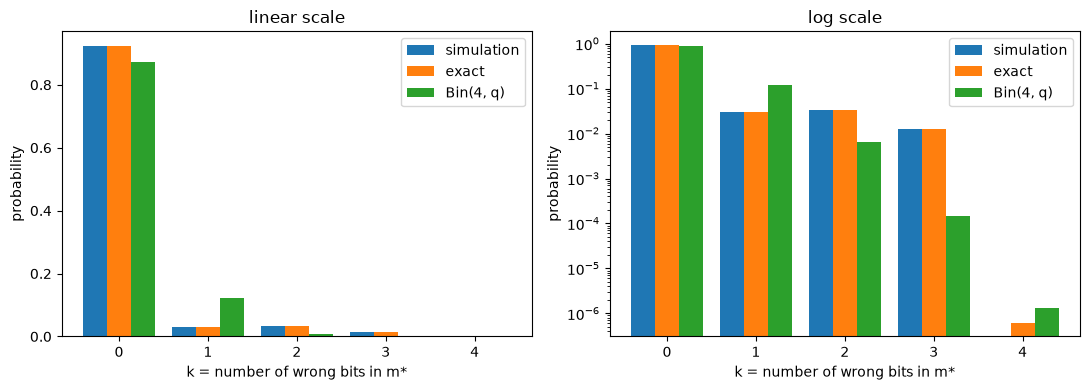

In [5]:
N3 = 1_000_000
m3, ms3 = simulate(N3, p)
k = (m3 != ms3).sum(axis=1)
emp = np.bincount(k, minlength=5) / N3

# exact distribution by enumerating all 2^7 channel error patterns (c = 0 w.l.o.g.)
exact = np.zeros(5)
for e in itertools.product([0, 1], repeat=7):
    e = np.array(e)
    w = e.sum()
    z_e = (e @ H) % 2
    pos = z_e[0] + 2 * z_e[1] + 4 * z_e[2]
    r_star = e.copy()
    if pos > 0:
        r_star[pos - 1] ^= 1
    exact[r_star[[2, 4, 5, 6]].sum()] += p**w * (1 - p)**(7 - w)

q = (emp * np.arange(5)).sum() / 4          # per-bit error rate of m*
bin_pmf = binom.pmf(np.arange(5), 4, q)

print(" k | empirical    | exact        | Bin(4, q)")
for i in range(5):
    print(f" {i} | {emp[i]:.6f}     | {exact[i]:.6f}     | {bin_pmf[i]:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
w = 0.27
x_ = np.arange(5)
for a, scale in zip(ax, ["linear", "log"]):
    a.bar(x_ - w, emp, w, label="simulation")
    a.bar(x_, exact, w, label="exact")
    a.bar(x_ + w, bin_pmf, w, label="Bin(4, q)")
    a.set_xticks(x_); a.set_xlabel("k = number of wrong bits in m*"); a.set_ylabel("probability")
    a.set_yscale(scale); a.set_title(f"{scale} scale"); a.legend()
plt.tight_layout(); plt.show()

**Comment.** The simulated histogram matches the exact distribution (the value $k=4$ is so rare, about $10^{-9}$, that it practically never occurs in a simulation).

The number of wrong bits **does not** follow a binomial distribution. A binomial law would require the four bits of $m^*$ to be wrong independently, with the same probability. Here the errors come in clusters: a failure needs at least $2$ corrupted channel bits, and then the decoder produces a wrong *codeword* that differs from the sent one in at least $3$ of the $7$ positions, so several message bits are often wrong at once. As a result $P(K=0)$ is larger and $P(K=2),P(K=3)$ are much larger than under $\mathrm{Bin}(4,q)$ with the same mean (on the log scale, the $\mathrm{Bin}(4,q)$ bars fall off geometrically, while the true probabilities for $k=1,2,3$ are of the same order). So $K$ is a non-trivial mixture determined by the code's structure, not a known standard distribution.

## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


In [6]:
# YOUR CODE GOES HERE

## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$

### Solution 3.1: CLT for the sample mean of inter-click times

The inter-click times are i.i.d. $X_k\sim\mathcal E(\nu_1)$ with $\nu_1=\dfrac{\text{team-id-number}}{10}+1$ (minutes$^{-1}$), so
$$E[X_k]=\frac1{\nu_1},\qquad \mathrm{Var}(X_k)=\frac1{\nu_1^{2}}.$$
By the CLT, for the sample mean $\bar X_n=\frac1n\sum_{k=1}^n X_k$,
$$\frac{\sqrt n\,(\bar X_n-1/\nu_1)}{1/\nu_1}\ \xrightarrow{d}\ \mathcal N(0,1)
\quad\Longrightarrow\quad
\bar X_n\ \approx\ \mathcal N\!\Bigl(\frac1{\nu_1},\ \frac1{n\nu_1^{2}}\Bigr)\ \text{for large }n.$$

We simulate $K=20\,000$ realizations of $\bar X_n$ for $n=5,10,50$, build the e.c.d.f. $\hat F_{\mathbf s}$ of the sample means, compare it with the c.d.f. of $\mathcal N(1/\nu_1,\,1/(n\nu_1^2))$, and report $\max_t|\hat F_{\mathbf s}(t)-F(t)|$.

nu1 = 2.9 per minute;  E[X] = 0.3448 min,  SD[X] = 0.3448 min
n =  5: mu = 0.3448, sigma = 0.1542, max diff = 0.05921
n = 10: mu = 0.3448, sigma = 0.1090, max diff = 0.04191
n = 50: mu = 0.3448, sigma = 0.0488, max diff = 0.02041


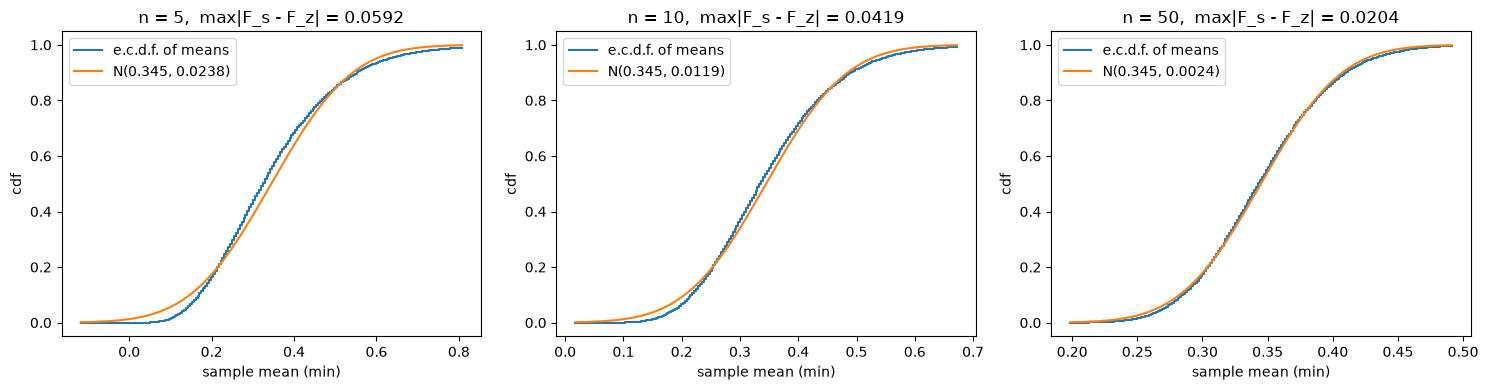

In [7]:
from scipy.stats import ecdf

nu1 = team_id / 10 + 1          # click rate of a single stored source, per minute
mu_X, sigma_X = 1 / nu1, 1 / nu1
print(f"nu1 = {nu1} per minute;  E[X] = {mu_X:.4f} min,  SD[X] = {sigma_X:.4f} min")

K = 20_000
ns = [5, 10, 50]

fig, axes = plt.subplots(1, len(ns), figsize=(5 * len(ns), 4))
for ax, n in zip(axes, ns):
    s = np.random.exponential(scale=1 / nu1, size=(K, n)).mean(axis=1)
    mu, sigma = 1 / nu1, 1 / (nu1 * np.sqrt(n))
    Fs = ecdf(s).cdf.evaluate
    Fz = norm(mu, sigma).cdf
    t = np.linspace(mu - 3 * sigma, mu + 3 * sigma, 200)
    d = np.max(np.abs(Fs(t) - Fz(t)))

    ax.step(t, Fs(t), where="post", label="e.c.d.f. of means")
    ax.plot(t, Fz(t), label=f"N({mu:.3f}, {sigma**2:.4f})")
    ax.set_title(f"n = {n},  max|F_s - F_z| = {d:.4f}")
    ax.set_xlabel("sample mean (min)"); ax.set_ylabel("cdf"); ax.legend()
    print(f"n = {n:2d}: mu = {mu:.4f}, sigma = {sigma:.4f}, max diff = {d:.5f}")

plt.tight_layout(); plt.show()

**Comment.** As expected from the CLT, the fit gets better as $n$ grows: the max gap between the simulated and the normal c.d.f. drops from about $0.06$ at $n=5$ to $0.02$ at $n=50$. Even $n=5$ isn't bad, though since the exponential distribution is skewed, the normal approximation still isn't great yet at that point.

### Solution 3.2: the maximal number of stored samples $N$

**(a) Event in terms of $S$.** Merging $N$ independent stored sources, each a Poisson process of clicks with rate $\nu_1$, gives a single Poisson process with rate $\nu=N\nu_1$. Let $M$ be the number of clicks during the first minute, $M\sim\mathrm{Poisson}(\nu)$, and let $S:=X_1+\dots+X_{100}$ be the arrival time of the $100$th click of the *merged* process, so now each $X_i\sim\mathcal E(\nu)$ i.i.d. and $S\sim\mathrm{Gamma}(100,\nu)$. Fewer than $100$ clicks occur during $[0,1]$ exactly when the $100$th click has not yet happened by time $1$, i.e.
$$\{\text{place is safe}\}=\{M<100\}=\{S>1\}.$$
We need the **largest** $N$ (equivalently $\nu=N\nu_1$) such that $P(S>1)\ge0.95$, i.e. $P(M\ge100)\le0.05$.

**(b) Bounds on $\nu$.**

- *Markov's inequality* ($M\ge0$): $\ P(M\ge100)\le \dfrac{E[M]}{100}=\dfrac{\nu}{100}$. Requiring $\dfrac{\nu}{100}\le0.05$ gives $\nu\le5$.
- *Chernoff bound* (Poisson upper tail, valid for $a>\nu$): $\ P(M\ge a)\le e^{-\nu}\Bigl(\dfrac{e\nu}{a}\Bigr)^{a}$. With $a=100$, we solve $e^{-\nu}(e\nu/100)^{100}=0.05$ numerically for $\nu$.
- *CLT*: $M\approx\mathcal N(\nu,\nu)$, so
$$P(M\ge100)\approx 1-\Phi\!\Bigl(\frac{100-\nu}{\sqrt\nu}\Bigr)\le0.05
\iff \frac{100-\nu}{\sqrt\nu}\ge z_{0.95}=1.645,$$
a quadratic inequality in $x=\sqrt\nu$: $x^2+1.645x-100\le0$, solved by $x\le\frac{-1.645+\sqrt{1.645^2+400}}2$.

In every case $N=\left\lfloor \nu_{\text{bound}}/\nu_1\right\rfloor$ (since $N$ must be an integer and $\nu$ is increasing in $N$).

In [8]:
from scipy.optimize import brentq

a = 100                          # safety threshold: fewer than 100 clicks per minute

nu_markov = a * 0.05                                  # Markov: nu <= 0.05 * a

chernoff_gap = lambda nu: np.exp(-nu) * (np.e * nu / a) ** a - 0.05
nu_chernoff = brentq(chernoff_gap, 1e-6, a - 1e-6)     # Chernoff: numeric root

z95 = norm.ppf(0.95)
x_clt = (-z95 + np.sqrt(z95**2 + 4 * a)) / 2
nu_clt = x_clt ** 2                                    # CLT: quadratic in sqrt(nu)

bounds = {}
for name, nu_bound in [("Markov", nu_markov), ("Chernoff", nu_chernoff), ("CLT", nu_clt)]:
    N_bound = int(nu_bound // nu1)
    bounds[name] = (nu_bound, N_bound)
    print(f"{name:9s}: nu <= {nu_bound:7.3f}  ->  N <= {nu_bound / nu1:6.3f}  ->  N = {N_bound}")

Markov   : nu <=   5.000  ->  N <=  1.724  ->  N = 1
Chernoff : nu <=  77.478  ->  N <= 26.716  ->  N = 26
CLT      : nu <=  84.849  ->  N <= 29.258  ->  N = 29


**(c)-(e) Simulation.** For each bound we take $N=\lfloor\nu_{\text{bound}}/\nu_1\rfloor$, simulate $K=50\,000$ realizations of $S=X_1+\dots+X_{100}$ with $X_i\sim\mathcal E(N\nu_1)$, and estimate $P(\text{safe})=P(S>1)$ by the fraction of samples with $S>1$; this should be $\ge0.95$, and as close to $0.95$ as possible for the *best* (least conservative) bound.

In [9]:
K2 = 50_000
n_clicks = 100

for name, (nu_bound, N) in bounds.items():
    nu = N * nu1
    S = np.random.exponential(scale=1 / nu, size=(K2, n_clicks)).sum(axis=1)
    p_safe = (S > 1).mean()
    print(f"{name:9s}: N = {N:2d}  (nu = {nu:.3f})  ->  empirical P(safe) = {p_safe:.4f}  (target >= 0.95)")

Markov   : N =  1  (nu = 2.900)  ->  empirical P(safe) = 1.0000  (target >= 0.95)
Chernoff : N = 26  (nu = 75.400)  ->  empirical P(safe) = 0.9958  (target >= 0.95)


CLT      : N = 29  (nu = 84.100)  ->  empirical P(safe) = 0.9518  (target >= 0.95)


**Comment.** The three bounds give quite different answers: Markov only allows $N=1$, Chernoff allows $N=26$, and the CLT allows $N=29$. The simulation confirms why: with $N=1$ the place is safe basically all the time ($P\approx1.000$), so Markov is way too cautious - it only uses the mean of $M$ and ignores everything else about the distribution. With $N=26$ (Chernoff) we're still comfortably above the target, at $\approx0.996$. With $N=29$ (CLT) we land almost exactly on $0.95$ ($\approx0.952$). So Markov is the loosest, Chernoff is a big improvement, and the CLT - even though it's "just" an approximation and not a real bound - turns out to be the most accurate of the three here. In practice: pick $N=26$ if you need an actual guarantee, or $N=29$ if you're fine trusting the normal approximation.

## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


### Solution 4.1(a): why $E(1/X)\ne 1/E(X)$

The map $g(x)=1/x$ is **nonlinear**: strictly convex on $(0,\infty)$ and strictly concave on $(-\infty,0)$. For a nonlinear $g$, Jensen's inequality gives $E[g(X)]\ne g(E[X])$ in general — equality holds only when $g$ is affine on the support of $X$ or $X$ is a.s. constant. Concretely, if $X>0$ a.s. then convexity of $1/x$ gives the strict inequality
$$E\!\left[\frac1X\right] > \frac1{E[X]}.$$
Intuitively, $E[1/X]$ averages the *reciprocals*, which blow up whenever $X$ is close to $0$; a handful of realizations near $0$ can dominate the average even though they barely affect $E[X]$ itself. $1/E[X]$ only ever sees the single aggregate number $E[X]$ and is blind to this effect.

### Solution 4.1(b): simulation for $X\sim\mathcal N(5,10)$

In [10]:
mu_N, var_N = 5, 10
n_b = 100
x_b = np.random.normal(mu_N, np.sqrt(var_N), size=n_b)
y_b = 1 / x_b

print(f"1 / mean(X) = {1 / x_b.mean():.4f}")
print(f"mean(Y)     = {y_b.mean():.4f}")
print(f"1 / E[X] (theoretical)     = {1 / mu_N:.4f}")
print(f"P(X <= 0) (theoretical)    = {norm.cdf(0, mu_N, np.sqrt(var_N)):.4f}")
print(f"# simulated |X| < 0.5 (near the pole of 1/x) = {(np.abs(x_b) < 0.5).sum()} out of {n_b}")

1 / mean(X) = 0.1916
mean(Y)     = 0.2902
1 / E[X] (theoretical)     = 0.2000
P(X <= 0) (theoretical)    = 0.0569
# simulated |X| < 0.5 (near the pole of 1/x) = 2 out of 100


**Comment.** $1/\bar X\approx0.192$ is close to the theoretical $1/E[X]=0.2$ - makes sense, since $\bar X$ is already a decent estimate of $E[X]=5$. But $\bar Y\approx0.290$ is further off and much less stable: $X\sim\mathcal N(5,10)$ has about a $5.7\%$ chance of being at or below $0$, and in our $100$ draws two values already landed close to $0$. Near zero, $1/X$ blows up, so a couple of extreme values can drag the average of $Y$ around a lot. That's basically a live demonstration of part (a): $1/X$ is very sensitive to what happens near $0$, which $E[X]$ alone says nothing about.

### Solution 4.1(c): Q-Q plots and scatterplots for $(X,Y)$ and $(X,Z)$

Let $X,Y\stackrel{\text{iid}}\sim\mathcal E(\lambda)$ and $Z:=\ln X+5$.

- $(X,Y)$ are **independent** (by construction) and **identically distributed** ($Y$ has the same $\mathcal E(\lambda)$ law as $X$). A scatterplot of independent pairs should look like a structureless cloud, and a Q-Q plot of two samples from the *same* distribution should fall close to the line $y=x$.
- $(X,Z)$ are **not independent** — $Z$ is a deterministic, strictly increasing function of $X$, so knowing $X$ tells us $Z$ exactly; their scatterplot must lie exactly on the curve $z=\ln x+5$. They are also **not identically distributed**: if $X\sim\mathcal E(\lambda)$ then $W:=\ln X$ has density $f_W(w)=\lambda e^{w}e^{-\lambda e^{w}}$ ($w\in\mathbb R$), i.e. a (shifted) **Gumbel (minimum)** distribution, not exponential. A monotone but nonlinear transform ($\ln$) preserves the *order* of the sample (so the Spearman rank correlation of $(X,Z)$ is exactly $1$) but changes the *shape* of the distribution — hence their Q-Q plot follows the curved map $z=\ln x+5$ rather than a straight diagonal.

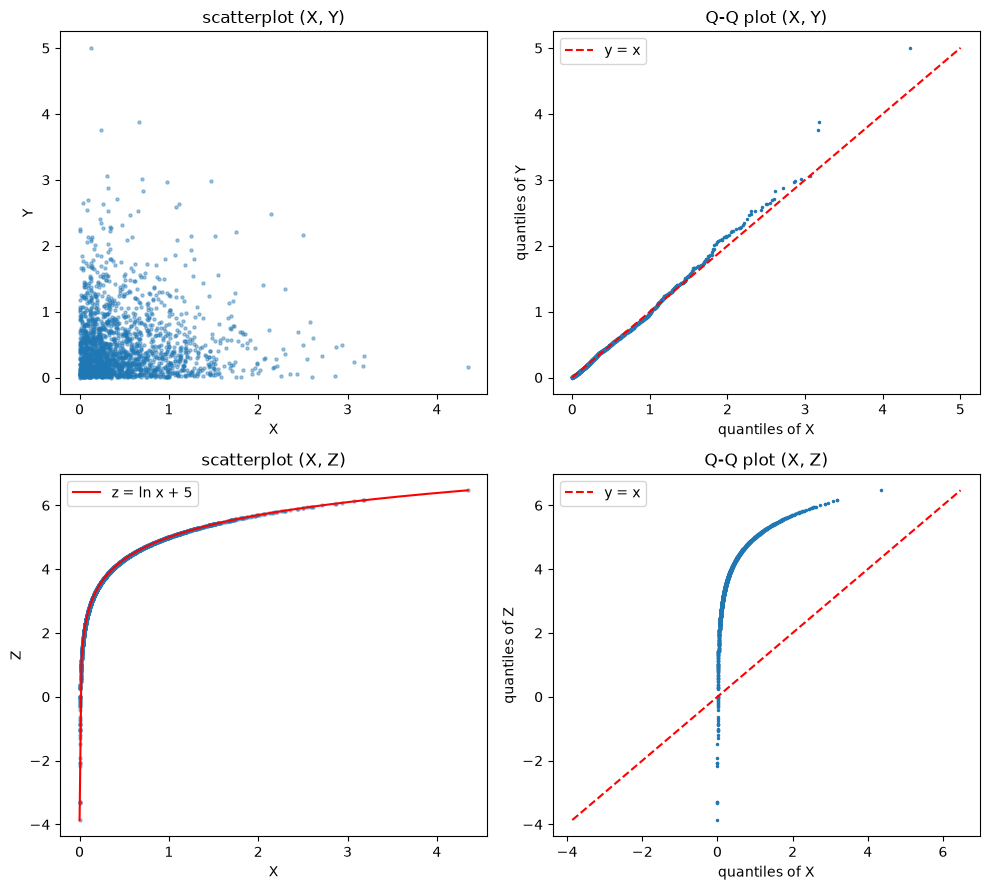

Pearson  corr(X, Y)  = -0.0031
Spearman corr(X, Y)  =  0.0007
Pearson  corr(X, Z)  =  0.7729
Spearman corr(X, Z)  =  1.0000


In [11]:
from scipy.stats import pearsonr, spearmanr

lam = 2
n_c = 2000
X_c = np.random.exponential(scale=1 / lam, size=n_c)
Y_c = np.random.exponential(scale=1 / lam, size=n_c)
Z_c = np.log(X_c) + 5

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

axes[0, 0].scatter(X_c, Y_c, s=5, alpha=0.4)
axes[0, 0].set_title("scatterplot (X, Y)"); axes[0, 0].set_xlabel("X"); axes[0, 0].set_ylabel("Y")

lims_xy = [min(X_c.min(), Y_c.min()), max(X_c.max(), Y_c.max())]
axes[0, 1].plot(np.sort(X_c), np.sort(Y_c), '.', ms=3)
axes[0, 1].plot(lims_xy, lims_xy, 'r--', label="y = x")
axes[0, 1].set_title("Q-Q plot (X, Y)"); axes[0, 1].set_xlabel("quantiles of X"); axes[0, 1].set_ylabel("quantiles of Y"); axes[0, 1].legend()

axes[1, 0].scatter(X_c, Z_c, s=5, alpha=0.4)
xs = np.linspace(X_c.min(), X_c.max(), 200)
axes[1, 0].plot(xs, np.log(xs) + 5, 'r-', label="z = ln x + 5")
axes[1, 0].set_title("scatterplot (X, Z)"); axes[1, 0].set_xlabel("X"); axes[1, 0].set_ylabel("Z"); axes[1, 0].legend()

lims_xz = [min(X_c.min(), Z_c.min()), max(X_c.max(), Z_c.max())]
axes[1, 1].plot(np.sort(X_c), np.sort(Z_c), '.', ms=3)
axes[1, 1].plot(lims_xz, lims_xz, 'r--', label="y = x")
axes[1, 1].set_title("Q-Q plot (X, Z)"); axes[1, 1].set_xlabel("quantiles of X"); axes[1, 1].set_ylabel("quantiles of Z"); axes[1, 1].legend()

plt.tight_layout(); plt.show()

print(f"Pearson  corr(X, Y)  = {pearsonr(X_c, Y_c)[0]: .4f}")
print(f"Spearman corr(X, Y)  = {spearmanr(X_c, Y_c)[0]: .4f}")
print(f"Pearson  corr(X, Z)  = {pearsonr(X_c, Z_c)[0]: .4f}")
print(f"Spearman corr(X, Z)  = {spearmanr(X_c, Z_c)[0]: .4f}")

**Comment.** For $(X,Y)$ the scatterplot is just a random cloud and both correlations are basically $0$, so they look independent - and the Q-Q plot sits right on the line $y=x$, so they're also the same distribution. For $(X,Z)$ it's the opposite: the scatterplot is a single curve $z=\ln x+5$, so knowing $X$ tells you $Z$ exactly - that's full dependence (Spearman correlation is exactly $1$). Pearson correlation is only $0.77$ though, because Pearson only picks up *linear* relationships, and this one is curved rather than straight. The Q-Q plot also clearly bends away from $y=x$, showing $Z$ isn't exponentially distributed the way $X$ is. So: $(X,Y)$ is the independent, identically-distributed pair, and $(X,Z)$ is the dependent, not-identically-distributed pair.

### Part 2: the coin game

#### (a) Type of $X$

$X$ counts Heads in 3 independent tosses of a fair coin (success probability $1/2$ each), so
$$X\sim\mathrm{Bin}(n=3,\ p=\tfrac12).$$
It is not Poisson (bounded support $\{0,1,2,3\}$; $n$ is small and $p$ is not small), not uniform ($P(X=k)=\binom3k/8$ is not constant) and not normal (it is discrete).

#### (b) $E(X)$ and $\mathrm{Var}(X)$

$$E(X)=np=1.5,\qquad \mathrm{Var}(X)=np(1-p)=0.75 .$$

In [12]:
from math import comb

n_rounds = 100
x = np.random.binomial(n=3, p=0.5, size=n_rounds)
print("sample mean     :", x.mean(),  "(theory 1.5)")
print("sample variance :", x.var(ddof=1), "(theory 0.75)")

sample mean     : 1.4 (theory 1.5)
sample variance : 0.9494949494949495 (theory 0.75)


**Comment.** The sample mean and sample variance fluctuate around the theoretical $1.5$ and $0.75$ (law of large numbers); the deviations are due to the modest sample size $n=100$ and shrink as $n$ grows.

#### (c) Is the friend's argument correct?

The friend computes $(E X)^2=2.25$, i.e. assumes $E(X^2)=(E X)^2$. This is the same fallacy as in 1(a): $E\,g(X)\ne g(E X)$ for non-linear $g$. Indeed
$$E(Y)=E(X^2)=\mathrm{Var}(X)+(E X)^2=0.75+2.25=3 .$$
Directly, with $P(X=k)=\binom3k/8$:
$$E(Y)=\sum_k k^2P(X=k)=\frac{0+3\cdot1+3\cdot4+1\cdot9}{8}=3,\qquad
E(Y^2)=\sum_k k^4P(X=k)=\frac{0+3\cdot1+3\cdot16+1\cdot81}{8}=16.5,$$
$$\mathrm{Var}(Y)=E(Y^2)-(E Y)^2=16.5-9=7.5 .$$
The expected net gain is $E(Y)-3=0$, so **the game is fair** and the friend is wrong.

exact E(Y) = 3.0  Var(Y) = 7.5
sample mean of Y     : 2.9
sample variance of Y : 8.979797979797977


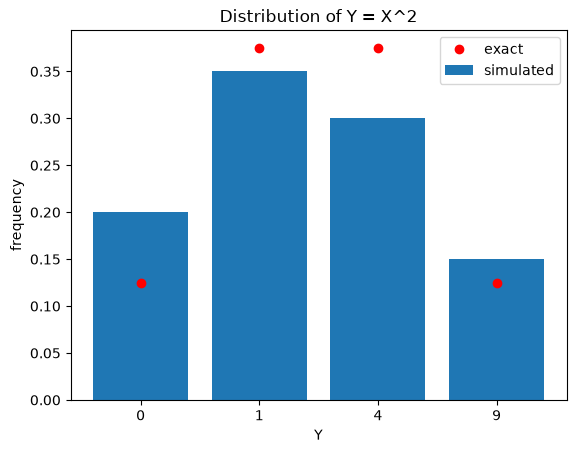

In [13]:
# exact values
pmf = {k: comb(3, k) / 8 for k in range(4)}
EY  = sum(k**2 * pr for k, pr in pmf.items())
EY2 = sum(k**4 * pr for k, pr in pmf.items())
VarY = EY2 - EY**2
print("exact E(Y) =", EY, " Var(Y) =", VarY)

# simulation
y = x**2
print("sample mean of Y     :", y.mean())
print("sample variance of Y :", y.var(ddof=1))

vals, counts = np.unique(y, return_counts=True)
plt.bar(vals.astype(str), counts / n_rounds, label="simulated")
plt.plot([str(k**2) for k in range(4)], [pmf[k] for k in range(4)], "ro", label="exact")
plt.xlabel("Y"); plt.ylabel("frequency"); plt.legend(); plt.title("Distribution of Y = X^2")
plt.show()

**Comment.** $\bar Y$ and $s_Y^2$ fluctuate around the exact values $3$ and $7.5$, not around $2.25$. $Y$ is very spread out (one round pays between £0 and £9), so $100$ rounds give a rather noisy estimate and $\bar Y$ can easily be a few tenths away from $3$; part (d) quantifies this.

#### (d) Confidence interval for $E(Y)$

By the CLT, $\bar Y\approx\mathcal N\bigl(E Y,\ \sigma_Y^2/n\bigr)$, so a 95% confidence interval is $\bar Y\pm\varepsilon$ with
$$\varepsilon=1.96\,\frac{s_Y}{\sqrt n}.$$

In [14]:
s_y = y.std(ddof=1)
eps = 1.96 * s_y / np.sqrt(n_rounds)
print(f"95% CI for E(Y): {y.mean():.3f} +- {eps:.3f}  ->  ({y.mean() - eps:.3f}, {y.mean() + eps:.3f})")
print("contains 3   :", y.mean() - eps < 3 < y.mean() + eps)
print("contains 2.9 :", y.mean() - eps < 2.9 < y.mean() + eps)

# rounds needed to tell fee 3 from fee 2.9 (difference 0.1), sigma_Y = sqrt(7.5)
sigma = np.sqrt(VarY)
n_excl = (1.96 * sigma / 0.10)**2    # eps <= 0.10: interval around 3 excludes 2.9
n_sep  = (1.96 * sigma / 0.05)**2    # eps <= 0.05: the two intervals do not overlap
print("n for eps <= 0.10 :", int(np.ceil(n_excl)))
print("n for eps <= 0.05 :", int(np.ceil(n_sep)))

95% CI for E(Y): 2.900 +- 0.587  ->  (2.313, 3.487)
contains 3   : True
contains 2.9 : True
n for eps <= 0.10 : 2882
n for eps <= 0.05 : 11525


**Conclusions.**

- With $n=100$ the half-length is about $1.96\cdot2.74/10\approx0.5$ (the exact value depends on the sample). The interval is wide and contains both $3$ and $2.9$, so **the simulation alone cannot tell whether the game is fair**; it can only fail to reject fairness. Fairness follows from the exact computation $E(Y)=3$.
- To distinguish the fee £3 from £2.9 we need $\varepsilon\lesssim0.1$, i.e. $n\ge(1.96\,\sigma_Y/0.1)^2\approx2\,900$ rounds (so that the interval around $\bar Y$ excludes £2.9), and about $11\,500$ rounds if the two confidence intervals should not overlap ($\varepsilon\le0.05$). The large numbers come from the high variance $\mathrm{Var}(Y)=7.5$ compared with the tiny difference $0.1$.

## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.